# Figure 5: Time Series - AASW and LSSW-mSW Seasonal Warming

## Import Packages

In [11]:
import pandas as pd
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, zoomed_inset_axes
import matplotlib.ticker as mticker
from matplotlib import path
from matplotlib.colors import TwoSlopeNorm
import matplotlib.cm as cm
from matplotlib.patches import Polygon
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors
import matplotlib.dates as mdates
import matplotlib.lines as mlines
import datetime

import xarray as xr
from netCDF4 import Dataset
from xgcm import Grid
import cmaps
import cmocean
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import os
import glob

import rioxarray

from dask.diagnostics import ProgressBar

from scipy.ndimage import gaussian_filter1d

from pyproj import Transformer

import seawater as sw
import gsw

import calendar

import pickle

## Import Data

In [12]:
ROOT = '/g/data/gv90/ad6790/amery-amisor'
os.chdir(f'{ROOT}/notebooks')

from fun_filtering import lowpass_filter

df = pd.read_parquet(f'{ROOT}/data/proc/04_filtered.parquet')

## Define Resuable Functions

In [13]:
def composite_seasonal_cycle(df, borehole, cat):
    # Create a mask to filter the specified borehole and cat
    sub = df[(df["borehole"] == borehole) & (df["cat"] == cat)].copy()
    sub = sub.sort_values("time")
    
    # Extract day of year from the time column
    sub["doy"] = sub["time"].dt.dayofyear + sub["time"].dt.hour / 24 + sub["time"].dt.minute / 1440
    
    # Round to nearest half-hour (1/48 of a day) since each MicroCAT records data with a half-hour interval, although due to time drift
    # the equivalent timestamp on different years may not be exactly the same time to the second
    sub["doy_bin"] = (sub["doy"] * 48).round() / 48

    # Define a dictionary to store the data and associated variables
    out = {"data": sub}

    # Create a pad either side which is twice the length of the cutoff_period
    n_pad = int((cutoff_period * 2) / sampling_interval)

    for key, col in [("temp", "conservative_temperature"), ("sal", "absolute_salinity")]:
        # Group temp or salinity by day of year
        grouped = sub.groupby("doy_bin")[col]

        # Calculate stats on the equivalent timestamp between different years
        stats = [("mean", grouped.mean()), ("std", grouped.std()), ("median", grouped.median()), ("q1", grouped.quantile(0.25)), ("q3", grouped.quantile(0.75))]

        for stat_name, series in stats:
            values = series.values
    
            # Since our lowpass filter uses .sosfiltfilt(), it applies the filter forwards and backwards through time
            # However, the data at the start and end of the year does not have data before and after it, respectively
            # We need to pad the data either side to treat the multi-year median as continuous
            # This is reasonable given that the seasonal data is naturally cyclic
            padded = np.concatenate([values[-n_pad:], values, values[:n_pad]])
    
            # Apply the filter function to the padded stat values
            filtered = lowpass_filter(padded, cutoff_period=cutoff_period, sampling_interval=sampling_interval, max_gap_hours=max_gap_hours)

            # Remove the padded data from the filtered data and save in the dictionary
            out[f"{key}_{stat_name}"] = filtered[n_pad:-n_pad]

        # Retain the DOY index to be able to plot the smoothed average values
        out["doy_index"] = series.index

    return out

## Define Parameters for Applying Filtering

Remove tidal and other short-term influences.

In [14]:
# Define the cutoff period for filtering in days (or hours)
cutoff_period_days = 30 # days
cutoff_period = cutoff_period_days*24 # hours
# cutoff_period = 48 # hours

# The sampling interval is 0.5 hours, given that each MicroCAT records observations every 30 minutes
sampling_interval=0.5

# Define a period of time in days for less than which we are comfortable interpolating for 
# Set this to 0 for no interpolation
interpolate_days = 7.5 # days
max_gap_hours=interpolate_days*24 # hours
# max_gap_hours=12 # hours

## AASW Onset Calculations

### Define the Determined AASW Onset DOYs

In [15]:
# Onset day-of-year for the arrival of AASW
AASW_ONSET = {2001: 68, 2003: 53, 2004: 90, 2005: 92, 2006: 121}
ISW_ONSET = {2001: 238, 2003: 245, 2004: 213, 2005: 222, 2006: 252}

### Define Magnitudes of Change and Duration

In [50]:
# Restrict search for temp arrival to a DOY window
SEARCH_DOY = (50, 180)
# Warming rate (degC per day) that we consider is onset
RATE_THRESHOLD = 0.00
# Arbitrary window after the onset to find the peak temp
AFTER_ONSET = 140

rows = []

# Extract the CTD data for this MicroCAT
microcat_data = df[(df["borehole"] == "AM02") & (df["cat"] == "1623")].sort_values("time")

# Iterate years contained in the microcat data
for year in sorted(microcat_data["time"].dt.year.unique()):
    if year not in AASW_ONSET:
        continue
        
    # Extract the CTD data for this year
    year_data = microcat_data[microcat_data["time"].dt.year == year]
    # Convert each timestep to a DOY value
    time_in_days = (year_data["time"] - year_data["time"].iloc[0]).dt.total_seconds().values / 86400
    # Extract the DOY values of each timestep
    doy = year_data["time"].dt.dayofyear.values

    # --------------- ARRIVAL: GRADIENT ---------------
    temp = year_data["conservative_temperature_smooth_30d"].values

    temp_gradient = np.gradient(temp, time_in_days)

    time_in_window = (doy >= SEARCH_DOY[0]) & (doy <= SEARCH_DOY[1]) & np.isfinite(temp_gradient)

    # Onset is the first timestep in the window where the warming rate exceeds the threshold
    threshold_reached = time_in_window & (temp_gradient > RATE_THRESHOLD)
    if not threshold_reached.any():
        continue
    index_of_onset = np.argmax(threshold_reached)          # argmax on a boolean array returns the first True

    # --------------- ARRIVAL: TEMPERATURE MINIMUM ---------------
    # The timestep with the lowest warming rate before the large gradient
    before_max_gradient = (time_in_days >= time_in_days[index_of_onset] - 10) & (time_in_days <= time_in_days[index_of_onset]) & np.isfinite(temp_gradient) & (temp_gradient >= 0)
    if before_max_gradient.any():
        index_of_start = np.flatnonzero(before_max_gradient)[np.argmin(temp_gradient[before_max_gradient])]
    else:
        index_of_start = index_of_onset

    # --------------- ARRIVAL: MANUALLY SELECTED ---------------
    temp_signal_time = (pd.Timestamp(year=int(year), month=1, day=1) + pd.Timedelta(days=AASW_ONSET[year] - 1))
    # The timestep closest to the manually selected arrival
    index_of_manual = np.argmin(np.abs((year_data["time"] - temp_signal_time).dt.total_seconds().values))

    # --------------- TEMPERATURE PEAK ---------------
    # Timesteps after onset
    time_after_onset = (time_in_days >= time_in_days[index_of_onset]) & (time_in_days <= time_in_days[index_of_onset] + AFTER_ONSET)

    # Find temp peaks where the warming rate goes from positive to zero or negative between consecutive timesteps, i.e. the temperature stops rising and starts falling
    turns = (temp_gradient[:-1] > 0) & (temp_gradient[1:] <= 0) & time_after_onset[:-1]
    temp_peak_index = np.flatnonzero(turns)

    # The last observed peak after the onset marks the END of the signal
    index_of_end = temp_peak_index[-1]
    end_time = year_data["time"].iloc[index_of_end]

    # --------------- SALINITY MINIMUM ---------------
    salt = year_data["absolute_salinity_smooth_30d"].values
    # The lowest salinity in the year
    index_of_salt_min = np.nanargmin(salt)
            
    # --------------- DURATION ---------------
    # From the manually selected arrival to the last temperature peak
    duration = (end_time - temp_signal_time).total_seconds() / 86400

    # # --------------- MAGNITUDES OF CHANGE ---------------
    temp_signal_magnitude = np.nanmax(temp) - temp[index_of_manual]
    salt_signal_magnitude = salt[index_of_manual] - salt[index_of_salt_min]

    # --------------- SUPERCOOLING ---------------
    freezing = year_data["conservative_freezing_point_temperature_smooth_30d"]
    temp = year_data["conservative_temperature_smooth_30d"]
    
    supercooling = (temp.notna() & freezing.notna() & (temp < freezing))
    
    # Identify the start and end of each continuous window
    supercooling_window = supercooling.ne(supercooling.shift()).cumsum()

    supercooling_windows = []
    
    for _, window in year_data[supercooling].groupby(supercooling_window[supercooling]):
        start_doy = int(window["time"].iloc[0].dayofyear)
        end_doy = int(window["time"].iloc[-1].dayofyear)

        supercooling_windows.append((start_doy, end_doy))
            
    rows.append(dict(
        year=year,
        arrival_doy=AASW_ONSET[year],
        auto_start_doy=doy[index_of_start],
        threshold_doy=doy[index_of_onset],
        end_doy=doy[index_of_end],
        salt_min_doy=doy[index_of_salt_min],
        salt_min=salt[index_of_salt_min],
        duration_days=duration,
        dT=temp_signal_magnitude,
        dS=salt_signal_magnitude,
        temp_peak_doys=[int(d) for d in doy[temp_peak_index]],
        temp_peaks=[round(float(t), 3) for t in temp.iloc[temp_peak_index]],
        supercooling_windows=supercooling_windows,
    ))

aasw = pd.DataFrame(rows)
print(aasw.round(3).to_string(index=False))

 year  arrival_doy  auto_start_doy  threshold_doy  end_doy  salt_min_doy  salt_min  duration_days    dT    dS      temp_peak_doys                       temp_peaks supercooling_windows
 2001           68              43             50      173           223    34.444        105.585 0.230 0.123 [61, 104, 130, 173] [-2.064, -1.945, -1.836, -1.849]         [(272, 317)]
 2003           53              53             53      181           183    34.376        128.292 0.235 0.200      [98, 141, 181]         [-1.895, -1.847, -1.858]         [(281, 343)]
 2004           90              50             50      175           178    34.381         85.562 0.249 0.163       [52, 72, 175]         [-2.102, -2.095, -1.843]         [(248, 296)]
 2005           92              48             50      153           185    34.428         61.437 0.265 0.119       [56, 81, 153]         [-2.099, -2.096, -1.834]         [(248, 305)]
 2006          121              66             66      167           180    34.3

### Calculate Average Temperature and Salinity Change

In [18]:
print(f"Mean dT: {aasw['dT'].mean():.2f} °C")
print(f"Mean dS: {aasw['dS'].mean():.2f} g/kg")

Mean dT: 0.24 °C
Mean dS: 0.15 g/kg


## LSSW-mSW Onset Calculations

### Define the Determined LSSW-mSW Onset DOYs

In [57]:
# Onset day-of-year for the arrival of AASW
LSSW_mSW_ONSET = {2006: 43, 2007: 78, 2008: 83, 2009: 30, 2010: 12}
LSSW_mSW_PEAK = {2006: 214, 2007: 213, 2008: 175, 2009: 157, 2010: 201}

### Define Magnitudes of Change and Duration

In [58]:
# Restrict search for temp arrival to a DOY window
SEARCH_DOY = (30, 120)
# Warming rate (degC per day) that we consider is onset
RATE_THRESHOLD = 0.001
# Arbitrary window after the onset to find the peak temp
AFTER_ONSET = 200

rows = []

# Extract the CTD data for this MicroCAT
microcat_data = df[(df["borehole"] == "AM03") & (df["cat"] == "4055")].sort_values("time")

# Iterate years contained in the microcat data
for year in sorted(microcat_data["time"].dt.year.unique()):
    if year not in LSSW_mSW_ONSET:
        continue
        
    # Extract the CTD data for this year
    year_data = microcat_data[microcat_data["time"].dt.year == year]
    # Convert each timestep to a DOY value
    time_in_days = (year_data["time"] - year_data["time"].iloc[0]).dt.total_seconds().values / 86400
    # Extract the DOY values of each timestep
    doy = year_data["time"].dt.dayofyear.values

    # --------------- ARRIVAL: GRADIENT ---------------
    temp = year_data["conservative_temperature_smooth_30d"].values

    temp_gradient = np.gradient(temp, time_in_days)

    time_in_window = (doy >= SEARCH_DOY[0]) & (doy <= SEARCH_DOY[1]) & np.isfinite(temp_gradient)

    # Onset is the first timestep in the window where the warming rate exceeds the threshold
    threshold_reached = time_in_window & (temp_gradient > RATE_THRESHOLD)
    if not threshold_reached.any():
        continue
    index_of_onset = np.argmax(threshold_reached)          # argmax on a boolean array returns the first True

    # --------------- ARRIVAL: MANUALLY SELECTED ---------------
    temp_signal_time = (pd.Timestamp(year=int(year), month=1, day=1) + pd.Timedelta(days=LSSW_mSW_ONSET[year] - 1))
    # The timestep closest to the manually selected arrival
    index_of_manual = np.argmin(np.abs((year_data["time"] - temp_signal_time).dt.total_seconds().values))

    # --------------- TEMPERATURE PEAK ---------------
    # Timesteps after onset
    time_after_onset = (time_in_days >= time_in_days[index_of_onset]) & (time_in_days <= time_in_days[index_of_onset] + AFTER_ONSET)

    # Find temp peaks where the warming rate goes from positive to zero or negative between consecutive timesteps, i.e. the temperature stops rising and starts falling
    turns = (temp_gradient[:-1] > 0) & (temp_gradient[1:] <= 0) & time_after_onset[:-1]
    temp_peak_index = np.flatnonzero(turns)

    # --------------- TEMPERATURE PEAK: MANUALLY SELECTED ---------------
    temp_peak_time = (pd.Timestamp(year=int(year), month=1, day=1) + pd.Timedelta(days=LSSW_mSW_PEAK[year]))
    # The timestep closest to the manually selected arrival
    index_of_end = np.argmin(np.abs((year_data["time"] - temp_peak_time).dt.total_seconds().values))
            
    # --------------- DURATION ---------------
    # From the manually selected arrival to the last temperature peak
    duration = (temp_peak_time - temp_signal_time).total_seconds() / 86400

    # # --------------- MAGNITUDES OF CHANGE ---------------
    temp_signal_magnitude = np.nanmax(temp) - temp[index_of_manual]

    # --------------- THERMAL DRIVING ---------------
    freezing = year_data["conservative_freezing_point_temperature_smooth_30d"].values
    thermal_driving = temp - freezing
    
    # Find the largest thermal driving in the year, and when it occurred
    if np.isfinite(thermal_driving).any():
        index_of_max_td = np.nanargmax(thermal_driving)
        max_td, max_td_doy = thermal_driving[index_of_max_td], doy[index_of_max_td]
    else:
        max_td, max_td_doy = np.nan, np.nan
            
    rows.append(dict(
        year=year,
        arrival_doy=LSSW_mSW_ONSET[year],
        threshold_doy=doy[index_of_onset],
        end_doy=doy[index_of_end] if index_of_end is not None else np.nan,
        duration_days=duration,
        dT=temp_signal_magnitude,
        max_thermal_driving=max_td,
        max_thermal_driving_doy=max_td_doy,
        temp_peak_doys=[int(d) for d in doy[temp_peak_index]],
        temp_peaks=[round(float(t), 3) for t in temp[temp_peak_index]],
    ))

lssw_msw = pd.DataFrame(rows)
print(lssw_msw.round(3).to_string(index=False))

 year  arrival_doy  threshold_doy  end_doy  duration_days    dT  max_thermal_driving  max_thermal_driving_doy                    temp_peak_doys                                               temp_peaks
 2006           43             43      214          172.0 0.152                0.293                      214 [69, 97, 134, 154, 186, 214, 236] [-2.202, -2.144, -2.153, -2.153, -2.116, -2.101, -2.122]
 2007           78             49      213          136.0 0.120                0.249                      162     [59, 120, 147, 162, 187, 213]          [-2.233, -2.16, -2.168, -2.145, -2.159, -2.145]
 2008           83             37      175           93.0 0.115                0.246                      172 [50, 69, 100, 133, 173, 175, 216]  [-2.252, -2.241, -2.184, -2.16, -2.146, -2.146, -2.246]
 2009           30             30      157          128.0 0.179                0.274                      144                [60, 82, 157, 219]                         [-2.213, -2.171, -2.136, -2.

### Calculate Average Temperature and Salinity Change

In [61]:
print(f"Mean dT: {lssw_msw['dT'].mean():.2f} °C")
print(f"Mean Duration: {lssw_msw['duration_days'].mean():.0f} Days")
print(f"Mean Max T*: {lssw_msw['max_thermal_driving'].mean():.2f} °C")
print("Max T*: 0.294 °C")

Mean dT: 0.15 °C
Mean Duration: 144 Days
Mean Max T*: 0.27 °C
Max T*: 0.294 °C


## Plots
### Define Constant and Common Variables

In [22]:
# Define global colour mapping for each year to ensure consistency across boreholes and MicroCATs
YEAR_COLOURS = {
    2001: "tab:blue",   2002: "tab:orange", 2003: "tab:green",
    2004: "tab:red",    2005: "tab:purple", 2006: "tab:brown",
    2007: "tab:pink",   2008: "tab:olive",  2009: "tab:cyan",
    2010: "darkblue",   2011: "crimson",    2012: "teal",
    2013: "goldenrod",
}

# Define a dictionary mapping each MicroCAT to it's pre-calculated average pressure
# Average pressure is the mean pressure on deployment
AVG_PRESSURES = {
    "1969": 441.1,    "1970": 581.6,   "1971": 743.4,
    "1623": 338.5,    "1624": 562.7,   "1174": 770.2,
    "4055": 661.4,    "4054": 872.2,   "3883": 1227.1,
    "1972": 550.4,    "1973": 693.0,   "1974": 814.7,
    "7327": 580.5,    "7326": 738.8,   "7322": 876.6,
    "7325": 551.4,    "7324": 680.8,   "7323": 790.3,
}

# Colours assigned to boreholes in month mode (when multiple boreholes are shown)
BOREHOLE_COLOURS = {
    "AM01": {"1969": "darkgreen", "1970": "forestgreen", "1971": "mediumseagreen"},
    "AM02": {"1623": "darkred", "1624": "red", "1174": "indianred"},
    "AM03": {"4055": "saddlebrown", "4054": "sandybrown", "3883": "peru"},
    "AM04": {"1972": "black", "1973": "grey", "1974": "darkgrey"},
    "AM05": {"7327": "indigo", "7326": "darkviolet", "7322": "mediumorchid"},
    "AM06": {"7325": "navy", "7324": "royalblue", "7323": "cornflowerblue"},
}

POSITION_INDEX = {"upper": 0, "middle": 1, "lower": 2}

raw_kw = dict(lw=0.8, alpha=0.2, zorder=1)
bandlines_kw = dict(label="_", lw=0.4, zorder=2)
band_kw = dict(hatch=None, alpha=0.2, zorder=2)
smooth_kw = dict(lw=1, zorder=4)
avg_kw = dict(lw=1, zorder=3)
year_arrival_kwargs = dict(linestyle='-', lw=1)

plt.rcParams.update({
    'font.size': 12,          # base size, everything else scales from it
    'axes.labelsize': 12,
    'axes.titlesize': 12,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
})

## Figure 5: AASW (a-b), LSSW-mSW (c-d)

In [66]:
# --- AASW at AM02 (top two panels) ---
# Define the borehole, and associated MicroCAT at that borehole
boreholes_aasw = [("AM02", "1623")]

data_gaps = [("2002-02-06", "2003-02-06")]
data_gaps = [(pd.Timestamp(a), pd.Timestamp(b)) for a, b in data_gaps]

# Define the limits of the y-axes for plots of temperature and salinity
ylim_temp_aasw = (-2.199, -1.701)
ylim_sal_aasw = (34.3, 34.7)

# --- LSSW/mSW at AM03 (bottom two panels) ---
# Define the borehole, and associated MicroCAT at that borehole
boreholes_lssw = [("AM03", "4055")]

# Define the limits of the y-axes for plots of temperature and salinity
ylim_temp_lssw = (-2.45, -1.95)
ylim_sal_lssw = (34.3, 34.7)

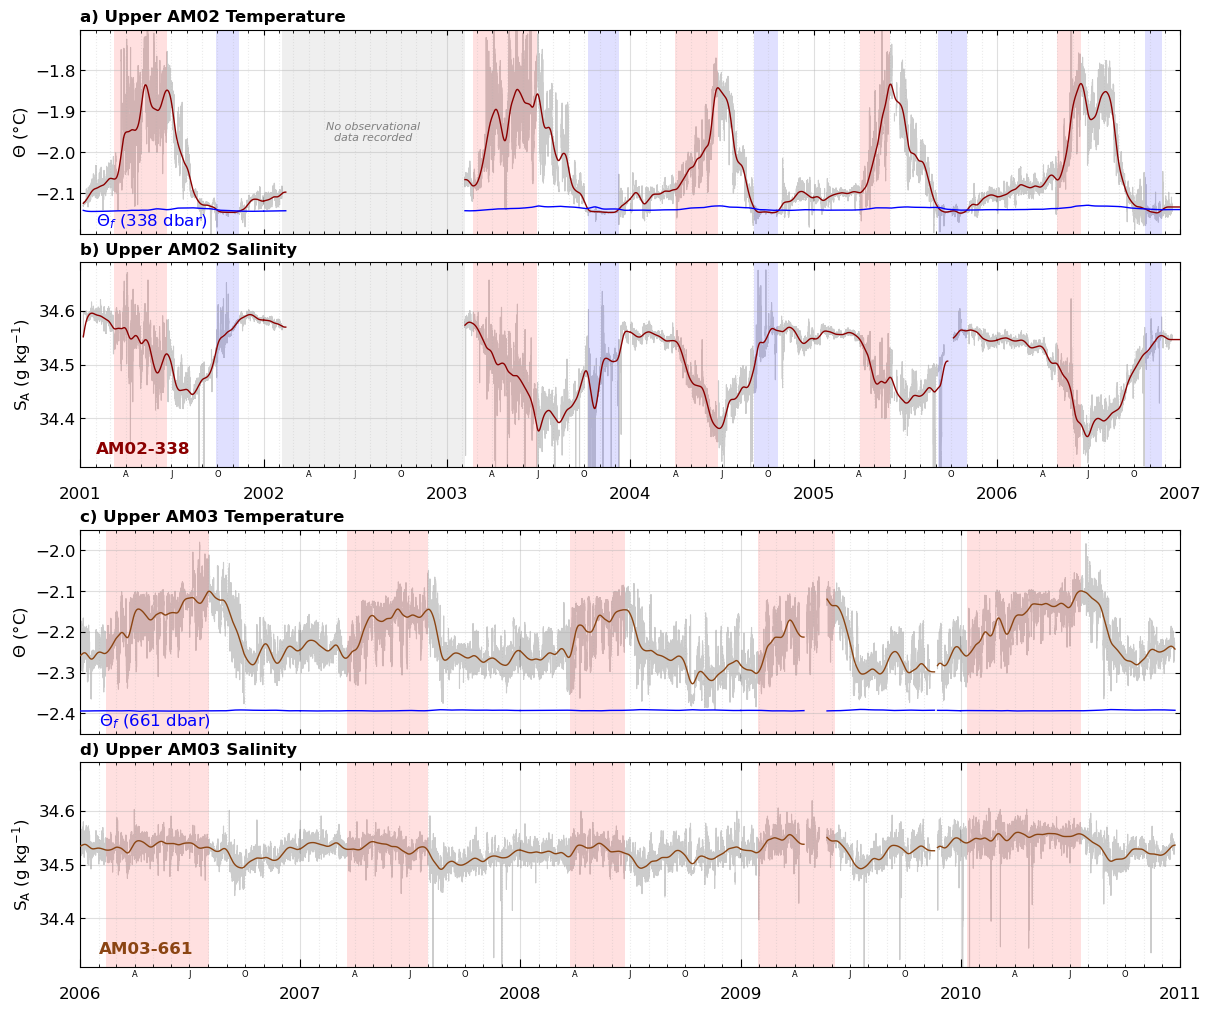

In [74]:
fig, (axT1, axS1, axT2, axS2) = plt.subplots(4, 1, figsize=(12, 10), layout='constrained')

axS1.sharex(axT1)
axS2.sharex(axT2)

axT1.tick_params(axis="x", which="both", labelbottom=False)
axT2.tick_params(axis="x", which="both", labelbottom=False)

# ---------------------------------------- TOP: AASW AT AM02 ----------------------------------------
all_years = []

for i, (bh, cat) in enumerate(boreholes_aasw):
    r = composite_seasonal_cycle(df, bh, cat)
    sub = r["data"]
    label = f"{bh}-{AVG_PRESSURES[cat]:.0f}"

    # Extract day of year and year from the time column
    sub["year"] = sub["time"].dt.year
    # Get the unique years in the subset
    years = sorted(sub["year"].unique())
    all_years += years

    # Retrieve the position of the iterated MicroCAT in the water column
    position = sub["water_column_position"].iloc[0]

    # Plot each individual year
    for year in years:
        first = year == years[0]

        # Filter the subset for the current year
        year_data = sub[sub["year"] == year]

        # Plot raw data
        axT1.plot(year_data["time"], year_data["conservative_temperature"], color="black", label="_", **raw_kw)
        axS1.plot(year_data["time"], year_data["absolute_salinity"], color="black", label="_", **raw_kw)

        # Plot smoothed data
        axT1.plot(year_data["time"], year_data["conservative_temperature_smooth_30d"], label=label if first else "_", color=BOREHOLE_COLOURS[bh][cat], **smooth_kw)
        axS1.plot(year_data["time"], year_data["absolute_salinity_smooth_30d"], label=label if first else "_", color=BOREHOLE_COLOURS[bh][cat], **smooth_kw)

        # Plot the freezing point temperature of seawater
        if position == "upper":
            axT1.plot(year_data["time"], year_data["conservative_freezing_point_temperature_smooth_30d"], label="_", color="blue", **smooth_kw)

    axT1.text(pd.Timestamp(f"{years[0]}-02-01"), 0.015, fr"$\Theta_f$ ({AVG_PRESSURES[cat]:.0f} dbar)", transform=axT1.get_xaxis_transform(), color="blue", va="bottom", ha="left", zorder=2)
    axS1.text(pd.Timestamp(f"{years[0]}-02-01"), 0.05, label, transform=axS1.get_xaxis_transform(), color=BOREHOLE_COLOURS[bh][cat], fontweight="bold", va="bottom", ha="left", zorder=2)

for _, event in aasw.iterrows():
    year = int(event["year"])

    # --------------- AASW DURATION BANDS ---------------
    arrival = (pd.Timestamp(year=year, month=1, day=1) + pd.Timedelta(days=event["arrival_doy"] - 1))

    end = (pd.Timestamp(year=year, month=1, day=1) + pd.Timedelta(days=event["end_doy"] - 1))

    for ax in (axT1, axS1):
        ax.axvspan(arrival, end, color="red", alpha=0.12, linewidth=0, zorder=1)

    # --------------- SUPERCOOLING DURATION BANDS ---------------
    for start_doy, end_doy in event["supercooling_windows"]:
        start_time = (pd.Timestamp(year=year, month=1, day=1) + pd.Timedelta(days=start_doy - 1))

        end_time = (pd.Timestamp(year=year, month=1, day=1) + pd.Timedelta(days=end_doy - 1))

        for ax in (axT1, axS1):
            ax.axvspan(start_time, end_time, color="blue", alpha=0.12, linewidth=0, zorder=1)

y0, y1 = min(all_years), max(all_years) + 1
axS1.set_xlim(pd.Timestamp(f"{y0}-01-01"), pd.Timestamp(f"{y1}-01-01"))

# Set the axis limits
axT1.set_ylim(ylim_temp_aasw[0], ylim_temp_aasw[1])
# Inset the salinity limits so ticks don't sit on the frame
axS1.set_ylim(ylim_sal_aasw[0] + 0.01, ylim_sal_aasw[1] - 0.01)

# Data gaps - only at AM02
for ax in (axT1, axS1):
    for g0, g1 in data_gaps:
        ax.axvspan(g0, g1, color="grey", alpha=0.12, lw=0, zorder=0)

for g0, g1 in data_gaps:
    axT1.text(g0 + (g1 - g0) / 2, sum(ylim_temp_aasw) / 2, "No observational\ndata recorded", fontsize=8, color="grey", ha="center", va="center", style="italic", zorder=1)

# ---------------------------------------- BOTTOM: LSSW/mSW AT AM03 ----------------------------------------
all_years = []

for i, (bh, cat) in enumerate(boreholes_lssw):
    r = composite_seasonal_cycle(df, bh, cat)
    sub = r["data"]
    label = f"{bh}-{AVG_PRESSURES[cat]:.0f}"

    # Extract day of year and year from the time column
    sub["year"] = sub["time"].dt.year
    # Get the unique years in the subset
    years = sorted(y for y in sub["year"].unique() if y in LSSW_mSW_ONSET)
    all_years += years

    # Retrieve the position of the iterated MicroCAT in the water column
    position = sub["water_column_position"].iloc[0]

    # Plot each individual year
    for year in years:
        first = year == years[0]

        # Filter the subset for the current year
        year_data = sub[sub["year"] == year]

        # Plot raw data
        axT2.plot(year_data["time"], year_data["conservative_temperature"], color="black", label="_", **raw_kw)
        axS2.plot(year_data["time"], year_data["absolute_salinity"], color="black", label="_", **raw_kw)

        # Plot smoothed data
        axT2.plot(year_data["time"], year_data["conservative_temperature_smooth_30d"], label=label if first else "_", color=BOREHOLE_COLOURS[bh][cat], **smooth_kw)
        axS2.plot(year_data["time"], year_data["absolute_salinity_smooth_30d"], label=label if first else "_", color=BOREHOLE_COLOURS[bh][cat], **smooth_kw)

        # Plot the freezing point temperature of seawater
        if position == "upper":
            axT2.plot(year_data["time"], year_data["conservative_freezing_point_temperature_smooth_30d"], label="_", color="blue", **smooth_kw)

    axT2.text(pd.Timestamp(f"{years[0]}-02-01"), 0.015, fr"$\Theta_f$ ({AVG_PRESSURES[cat]:.0f} dbar)", transform=axT2.get_xaxis_transform(), color="blue", va="bottom", ha="left", zorder=2)
    axS2.text(pd.Timestamp(f"{years[0]}-02-01"), 0.05, label, transform=axS2.get_xaxis_transform(), color=BOREHOLE_COLOURS[bh][cat], fontweight="bold", va="bottom", ha="left", zorder=2)

# LSSW/mSW events at AM03
for _, event in lssw_msw.iterrows():
    year = int(event["year"])

    # Skip years where no temperature peak was found, since there's no end to the band
    if pd.isna(event["end_doy"]):
        continue

    # --------------- LSSW/mSW DURATION BANDS ---------------
    arrival = (pd.Timestamp(year=year, month=1, day=1) + pd.Timedelta(days=event["arrival_doy"] - 1))

    end = (pd.Timestamp(year=year, month=1, day=1) + pd.Timedelta(days=event["end_doy"] - 1))

    for ax in (axT2, axS2):
        ax.axvspan(arrival, end, color="red", alpha=0.12, linewidth=0, zorder=1)

y0, y1 = min(all_years), max(all_years) + 1
axS2.set_xlim(pd.Timestamp(f"{y0}-01-01"), pd.Timestamp(f"{y1}-01-01"))

# Set the axis limits
axT2.set_ylim(ylim_temp_lssw[0], ylim_temp_lssw[1])
# Inset the salinity limits so ticks don't sit on the frame
axS2.set_ylim(ylim_sal_lssw[0] + 0.01, ylim_sal_lssw[1] - 0.01)

# ---------------------------------------- FORMATTING FOR BOTH ----------------------------------------
# Date ticks on the two salinity panels, which carry the time axis for each pair
for ax in (axS1, axS2):
    # Add years as major ticks
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    # Add months as minor ticks
    ax.xaxis.set_minor_locator(mdates.MonthLocator())
    ax.xaxis.set_minor_formatter(mticker.FuncFormatter(lambda x, pos: (lambda d: d.strftime("%b")[0] if d.month in {4, 7, 10} else "")(mdates.num2date(x))))
    ax.tick_params(axis="x", which="minor", labelsize=6, pad=2)
    ax.tick_params(axis="x", which="major", pad=14, length=6)

for ax in (axT1, axS1, axT2, axS2):
    ax.tick_params(axis="both", which="both", direction="in", top=True, right=True)
    ax.grid(True, which="major", linestyle="-", alpha=0.4)
    ax.grid(True, which="minor", linestyle=":", alpha=0.25)

# Fixed 0.1 interval on temperature
axT1.yaxis.set_major_locator(mticker.MultipleLocator(0.1))
axT2.yaxis.set_major_locator(mticker.MultipleLocator(0.1))

bh1, cat1 = boreholes_aasw[0]
bh2, cat2 = boreholes_lssw[0]
axT1.set_title(f"a) Upper {bh1} Temperature", loc='left', fontweight="bold")
axS1.set_title(f"b) Upper {bh1} Salinity", loc='left', fontweight="bold")
axT2.set_title(f"c) Upper {bh2} Temperature", loc='left', fontweight="bold")
axS2.set_title(f"d) Upper {bh2} Salinity", loc='left', fontweight="bold")

# Label the y-axis
for ax in (axT1, axT2):
    ax.set_ylabel(r"$\Theta$ (°C)")
for ax in (axS1, axS2):
    ax.set_ylabel(r"$\mathrm{S_{A} \ (g \ kg^{-1}})$")

fig.savefig('/g/data/gv90/ad6790/amery-amisor/notebooks/figures/ObsTimeSeriesAASW_LSSW.jpg', format='jpg', dpi=600)
plt.show()